<a href="https://colab.research.google.com/github/Alisherbakh/receipt-reader/blob/main/receipt_reader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Receipt Reader — Qwen2-VL + QLoRA

Reads a receipt photo and returns the items, their prices and the total as JSON.

- Model: `Qwen/Qwen2-VL-2B-Instruct` (4-bit + LoRA)
- Training: `naver-clova-ix/cord-v2` (400 receipts)
- Test: CORD test + `HumynLabs/Korean_Receipts_Dataset` (20 Korean receipts)

Runtime → Change runtime type → **T4 GPU**

In [ ]:
!pip install -q -U trl peft bitsandbytes

In [ ]:
import json, re, torch
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/receipt_reader'
else:
    OUT = '/content/receipt_reader'

MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'
N_TRAIN = 400
N_TEST = 30

print(torch.__version__, torch.cuda.get_device_name(0))

2.14.1+cu130 Tesla T4


## 1. Model

In [ ]:
processor = AutoProcessor.from_pretrained(MODEL_ID, min_pixels=128 * 28 * 28, max_pixels=768 * 28 * 28)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',
    dtype=torch.float16,
)

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (2 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [ ]:
PROMPT = (
    'Read this receipt. Return only JSON in this format: '
    '{"items": [{"name": "...", "count": "...", "price": "..."}], "total": "..."}'
)

def messages_for(answer=None):
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT}]}]
    if answer is not None:
        messages.append({'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]})
    return messages

def read_receipt(image, max_new_tokens=512):
    text = processor.apply_chat_template(messages_for(), add_generation_prompt=True)
    inputs = processor(text=[text], images=[image.convert('RGB')], return_tensors='pt').to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0]

## 2. Dataset: CORD

In [ ]:
cord = load_dataset('naver-clova-ix/cord-v2')
cord

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

data/train-00001-of-00004-7dbbe248962764(…): downloading bytes:           |  0.00B            

... (8 outputs left out)

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
    test: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
})

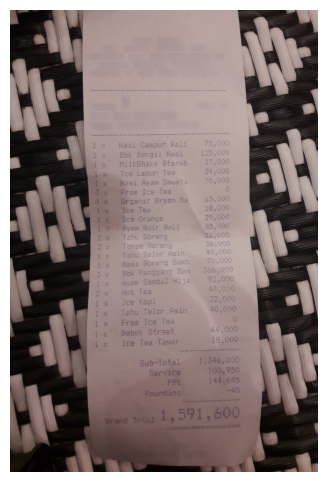

{
  "items": [
    {
      "name": "Nasi Campur Bali",
      "count": "1 x",
      "price": "75,000"
    },
    {
      "name": "Bbk Bengil Nasi",
      "count": "1 x",
      "price": "125,000"
    },
    {
      "name": "MilkShake Starwb",
      "count": "1 x",
      "price": "37,000"
    },
    {
      "name": "Ice Lemon Tea",
      "count": "1 x",
      "price": "24,000"
    },
    {
      "name": "Nasi Ayam Dewata",
      "count": "1 x",
      "price": "70,000"
    },
    {
      "name": "Free Ice Tea",
      "count": "3 x",
      "price": "0"
    },
    {
      "name": "Organic Green Sa",
      "count": "1 x",
      "price": "65,000"
    },
    {
      "name": "Ice Tea",
      "count": "1 x",
      "price": "18,000"
    },
    {
      "name": "Ice Orange",
      "count": "1 x",
      "price": "29,000"
    },
    {
      "name": "Ayam Suir Bali",
      "count": "1 x",
      "price": "85,000"
    },
    {
      "name": "Tahu Goreng",
      "count": "2 x",
      "price": "36,000"
   

In [ ]:
def text_of(value):
    if isinstance(value, list):
        return ' '.join(text_of(v) for v in value)
    if value is None or isinstance(value, dict):
        return ''
    return str(value)

def to_target(ground_truth):
    parse = json.loads(ground_truth)['gt_parse']
    menu = parse.get('menu', [])
    if isinstance(menu, dict):
        menu = [menu]
    items = [
        {'name': text_of(m.get('nm')), 'count': text_of(m.get('cnt')), 'price': text_of(m.get('price'))}
        for m in menu if isinstance(m, dict)
    ]
    total = parse.get('total', {})
    if isinstance(total, list):
        total = total[0] if total else {}
    if not isinstance(total, dict):
        total = {}
    return {'items': items, 'total': text_of(total.get('total_price'))}

sample = cord['train'][0]
plt.figure(figsize=(4, 6))
plt.imshow(sample['image'])
plt.axis('off')
plt.show()
print(json.dumps(to_target(sample['ground_truth']), indent=2, ensure_ascii=False))

In [ ]:
def to_example(row):
    answer = json.dumps(to_target(row['ground_truth']), ensure_ascii=False)
    messages = messages_for(answer)
    return {'images': [row['image']], 'prompt': messages[:1], 'completion': messages[1:]}

train_ds = (
    cord['train']
    .shuffle(seed=42)
    .select(range(N_TRAIN))
    .map(to_example, remove_columns=['image', 'ground_truth'])
)

test_rows = [r for r in cord['test'] if to_target(r['ground_truth'])['total']][:N_TEST]

print(train_ds)
print('test:', len(test_rows))

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Dataset({
    features: ['images', 'prompt', 'completion'],
    num_rows: 400
})
test: 30


## 3. Evaluation functions

In [ ]:
def digits(value):
    return re.sub(r'\D', '', str(value))

def parse_json(text):
    match = re.search(r'\{.*\}', text, re.S)
    if not match:
        return None
    try:
        data = json.loads(match.group(0))
    except json.JSONDecodeError:
        return None
    return data if isinstance(data, dict) else None

def items_of(pred):
    items = pred.get('items', []) if pred else []
    return [i for i in items if isinstance(i, dict)] if isinstance(items, list) else []

def score(pred, target):
    gt_prices = [digits(i['price']) for i in target['items'] if digits(i['price'])]
    pred_prices = [digits(i.get('price', '')) for i in items_of(pred)]
    hits = sum(1 for p in gt_prices if p in pred_prices)
    return {
        'json_ok': pred is not None,
        'total_ok': pred is not None and digits(pred.get('total', '')) == digits(target['total']),
        'price_recall': hits / len(gt_prices) if gt_prices else 1.0,
    }

def evaluate(rows):
    scores = [score(parse_json(read_receipt(r['image'])), to_target(r['ground_truth'])) for r in rows]
    return pd.DataFrame(scores).mean().round(3)

## 4. Korean receipts

In [ ]:
from huggingface_hub import hf_hub_download
from PIL import Image

KOREAN_TOTALS = {
    1: '60000', 2: '14000', 3: '157600', 4: '60000', 5: '157600',
    6: '31400', 7: '13000', 8: '23200', 9: '3120', 10: '3120',
    11: '36000', 12: '30600', 13: '100000', 14: '25500', 15: '12000',
    16: '11700', 17: '7000', 18: '14500', 19: '7500', 20: '17300',
}

korean = [
    Image.open(hf_hub_download('HumynLabs/Korean_Receipts_Dataset', f'Kgen_Korean Receipts_1005_{i}.JPEG', repo_type='dataset')).convert('RGB')
    for i in KOREAN_TOTALS
]

def korean_eval():
    rows = []
    for (i, true_total), image in zip(KOREAN_TOTALS.items(), korean):
        pred = parse_json(read_receipt(image))
        total = digits(pred.get('total', '')) if pred else ''
        rows.append({'id': i, 'json_ok': pred is not None, 'pred_total': total,
                     'true_total': true_total, 'total_ok': total == true_total})
    return pd.DataFrame(rows)

print(len(korean))

Kgen_Korean Receipts_1005_1.JPEG: reconstructing file:   0%|          |  0.00B / 1.20MB            

Kgen_Korean Receipts_1005_1.JPEG: downloading bytes:           |  0.00B            

Kgen_Korean Receipts_1005_2.JPEG: reconstructing file:   0%|          |  0.00B / 1.17MB            

Kgen_Korean Receipts_1005_2.JPEG: downloading bytes:           |  0.00B            

Kgen_Korean Receipts_1005_3.JPEG: reconstructing file:   0%|          |  0.00B / 1.20MB            

Kgen_Korean Receipts_1005_3.JPEG: downloading bytes:           |  0.00B            

... (31 outputs left out)

Kgen_Korean Receipts_1005_19.JPEG: downloading bytes:           |  0.00B            

Kgen_Korean Receipts_1005_20.JPEG: reconstructing file:   0%|          |  0.00B / 1.24MB            

Kgen_Korean Receipts_1005_20.JPEG: downloading bytes:           |  0.00B            

20


## 5. Before fine-tuning

In [ ]:
before = evaluate(test_rows)
korean_before = korean_eval()
print(before)
print('korean total_ok:', korean_before['total_ok'].mean().round(3))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


json_ok         1.000
total_ok        0.867
price_recall    0.822
dtype: float64
korean total_ok: 0.6


In [ ]:
row = test_rows[0]
print(read_receipt(row['image']))
print(json.dumps(to_target(row['ground_truth']), ensure_ascii=False))

```json
{
  "items": [
    {
      "name": "Ticket",
      "count": 2,
      "price": "60,000"
    }
  ],
  "total": "60,000"
}
```
{"items": [{"name": "-TICKET CP", "count": "2", "price": "60.000"}], "total": "60.000"}


## 6. QLoRA fine-tuning

In [ ]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=['q_proj', 'v_proj'],
    task_type='CAUSAL_LM',
)

training_args = SFTConfig(
    output_dir=f'{OUT}/checkpoints',
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,
    logging_steps=10,
    save_strategy='steps',
    save_steps=25,
    save_total_limit=2,
    fp16=True,
    gradient_checkpointing=True,
    max_length=None,
    completion_only_loss=True,
    report_to='none',
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    processing_class=processor,
    peft_config=lora_config,
)

for p in trainer.model.parameters():
    if p.requires_grad:
        p.data = p.data.float()

trainer.model.print_trainable_parameters()

trainable params: 1,089,536 || all params: 2,210,075,136 || trainable%: 0.0493


In [ ]:
trainer.train()
trainer.save_model(f'{OUT}/adapter')
processor.save_pretrained(f'{OUT}/adapter')

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Step,Training Loss
10,0.103098
20,0.088612
30,0.083187
40,0.073679
50,0.100599
60,0.056379
70,0.087962
80,0.071624
90,0.070703
100,0.058543


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

['/content/receipt_reader/adapter/processor_config.json']

## 7. After fine-tuning

In [ ]:
model = trainer.model
model.eval()
model.config.use_cache = True

after = evaluate(test_rows)
korean_after = korean_eval()

results = pd.DataFrame({'before': before, 'after': after})
results.loc['korean_total_ok'] = [korean_before['total_ok'].mean().round(3), korean_after['total_ok'].mean().round(3)]
results

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


,before,after
json_ok,1.000,1.000
total_ok,0.867,0.967
price_recall,0.822,0.933
korean_total_ok,0.600,0.900


In [ ]:
korean_after.merge(korean_before[['id', 'pred_total']], on='id', suffixes=('', '_before'))

,id,json_ok,pred_total,true_total,total_ok,pred_total_before
0,1,True,60000,60000,True,60000
1,2,True,14000,14000,True,11500
2,3,True,143273,157600,False,143273
3,4,True,60000,60000,True,60000
4,5,True,157600,157600,True,157600
5,6,True,31400,31400,True,31400
6,7,True,13000,13000,True,
7,8,False,,23200,False,25200
8,9,True,3120,3120,True,3120
9,10,True,3120,3120,True,0


## 8. Demo: upload your own receipt

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


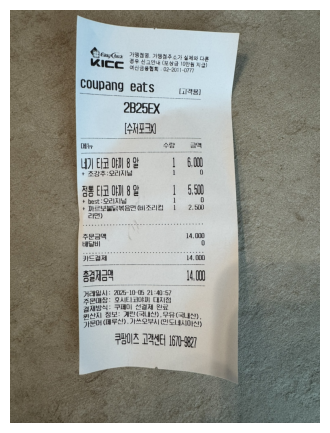

        name count price
네기 타코 야채 8 양     1 6,000
정통 타코 야채 8 양     1 5,500
Jami: 14,000
Mahsulotlar yig'indisi: 11500 | mos: False


In [ ]:
from google.colab import files
from PIL import Image
import io

def show_receipt(image):
    pred = parse_json(read_receipt(image))
    plt.figure(figsize=(4, 6))
    plt.imshow(image)
    plt.axis('off')
    plt.show()
    if pred is None:
        print('Could not read JSON')
        return
    table = pd.DataFrame(items_of(pred))
    print(table.to_string(index=False) if len(table) else 'No items found')
    print('Total:', pred.get('total', ''))
    prices = [int(digits(i.get('price', ''))) for i in items_of(pred) if digits(i.get('price', ''))]
    if prices and digits(pred.get('total', '')):
        print('Sum of items:', sum(prices), '| matches:', sum(prices) == int(digits(pred['total'])))

show_receipt(korean[1])

In [ ]:
uploaded = files.upload()
for name, data in uploaded.items():
    show_receipt(Image.open(io.BytesIO(data)).convert('RGB'))

## 9. Later: load the saved adapter

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


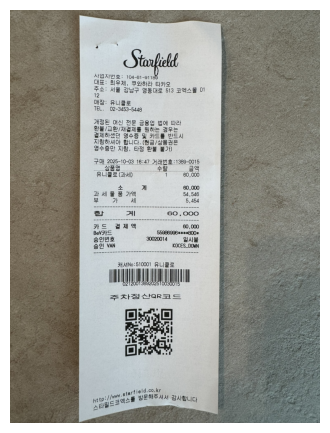

name count  price
 삼플로     1 60,000
Jami: 60,000
Mahsulotlar yig'indisi: 60000 | mos: True


In [ ]:
base = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID, quantization_config=bnb_config, device_map='auto', dtype=torch.float16
)
processor = AutoProcessor.from_pretrained(f'{OUT}/adapter')
model = PeftModel.from_pretrained(base, f'{OUT}/adapter')
model.eval()

show_receipt(korean[0])